In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
data = pd.read_csv("housing.csv")

copy_data = data.copy()
data.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [57]:
## removing null values
copy_data.dropna(inplace=True)

if 'ocean_proximity' in copy_data.columns:
    copy_data = copy_data.join(pd.get_dummies(copy_data['ocean_proximity'],dtype=float))
copy_data.drop(['ocean_proximity'], axis=1, inplace=True)


copy_data.info()

<class 'pandas.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   <1H OCEAN           20433 non-null  float64
 10  INLAND              20433 non-null  float64
 11  ISLAND              20433 non-null  float64
 12  NEAR BAY            20433 non-null  float64
 13  NEAR OCEAN          20433 non-null  float64
dtypes: float64(14)
memory usage: 2.3 MB


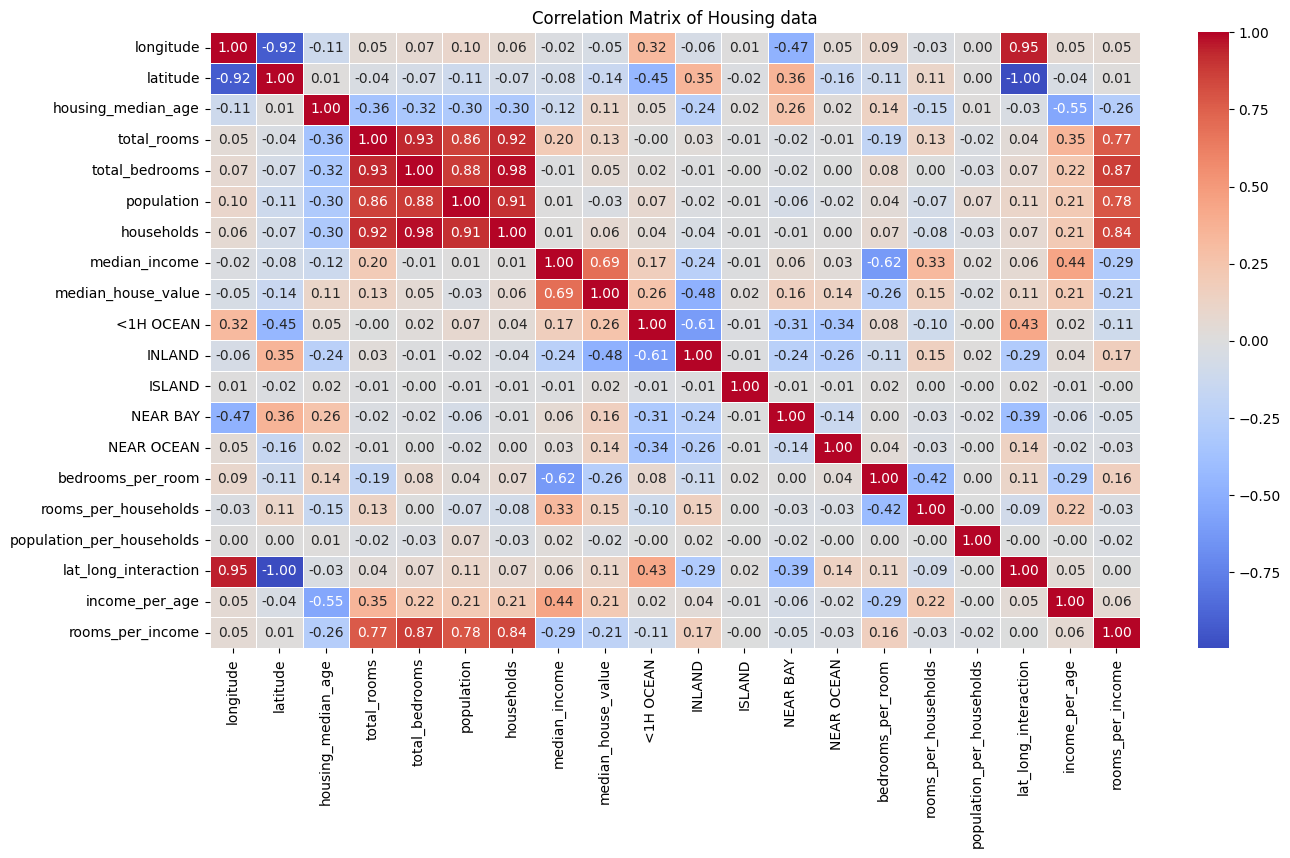

In [58]:
copy_data['bedrooms_per_room'] = copy_data['total_bedrooms']/copy_data['total_rooms']
copy_data['rooms_per_households'] = copy_data['total_rooms']/copy_data['households']
copy_data['population_per_households'] = copy_data['population']/copy_data['households']
copy_data['lat_long_interaction'] = (
    copy_data["latitude"] * copy_data["longitude"]
)
copy_data['income_per_age'] = copy_data['median_income']/copy_data['housing_median_age']
copy_data['rooms_per_income'] = copy_data['total_rooms']/copy_data['median_income']


corr_matrix = copy_data.corr(numeric_only=True)
plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
# Add a title
plt.title("Correlation Matrix of Housing data")
# Display the plot
plt.show()

copy_data.drop(['households','population','total_rooms','total_bedrooms'],axis=1,inplace=True)



In [59]:
copy_data.describe()

,longitude,latitude,housing_median_age,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedrooms_per_room,rooms_per_households,population_per_households,lat_long_interaction,income_per_age,rooms_per_income
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,3.871162,206864.413155,0.442128,0.317917,0.000245,0.111095,0.128615,0.213039,5.431344,3.071533,-4264.646279,0.201593,768.857343
std,2.003578,2.136348,12.591805,1.899291,115435.667099,0.496652,0.465678,0.015641,0.314257,0.334782,0.057983,2.482946,10.438269,323.948866,0.273770,618.697124
min,-124.350000,32.540000,1.000000,0.499900,14999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.846154,0.692308,-5207.673000,0.009613,0.533330
25%,-121.800000,33.930000,18.000000,2.563700,119500.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.175427,4.441441,2.429032,-4601.363200,0.080393,392.177778
50%,-118.490000,34.260000,29.000000,3.536500,179700.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.203162,5.230769,2.817582,-4060.373500,0.126746,617.209489
75%,-118.010000,37.720000,37.000000,4.744000,264700.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.239821,6.052381,3.281513,-4004.280600,0.218821,960.882353
max,-114.310000,41.950000,52.000000,15.000100,500001.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,141.909091,1243.333333,-3753.968400,7.500050,14132.195608


In [60]:
from sklearn.preprocessing import StandardScaler, RobustScaler

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()



standard_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "median_income",
    "rooms_per_households",
    "population_per_households",
    "lat_long_interaction",
    "income_per_age",
    "rooms_per_income"
]
robust_features = [
    "bedrooms_per_room"
]

copy_data[standard_features] = (
    standard_scaler.fit_transform(
        copy_data[standard_features]
    )
)


copy_data[robust_features] = (
    robust_scaler.fit_transform(
        copy_data[robust_features]
    )
)


y = np.log1p(copy_data["median_house_value"])


X = copy_data.drop(
    columns=["median_house_value"]
)



In [74]:
import pandas as pd
from datetime import datetime
from pathlib import Path
# -----------------------------------
# EXPERIMENT DETAILS FUNCTION
# -----------------------------------
def addRecord(rmse,r2_val,r2_train,changes,x_train,x_val):
    results_row = {
        "rmse": rmse,
        "r2_score_val": r2_val,
        "r2_score_train":r2_train,
        "timestamp": datetime.now(),
        "changes":changes,

        # useful extra columns
        "num_features": x_train.shape[1],
        "train_size": len(x_train),
        "val_size": len(x_val),
        "model": "LinearRegression"
    }
    results_path = "results.csv"

    if Path(results_path).exists():

        results_df = pd.read_csv(results_path)

        # auto increment id
        next_id = len(results_df) + 1

        results_row["id"] = next_id

        results_df = pd.concat(
            [
                results_df,
                pd.DataFrame([results_row])
            ],
            ignore_index=True
        )
    else:
        results_row["id"] = 1

        results_df = pd.DataFrame([results_row])

    results_df = results_df[
        [
            "id",
            "changes",
            "rmse",
            "r2_score_val",
            "r2_score_train",
            "num_features",
            "train_size",
            "val_size",
            "model",
            "timestamp"
        ]
    ]

    results_df.to_csv(
        results_path,
        index=False
    )

    print("\nResults saved to results.csv")


In [62]:
from sklearn.model_selection import train_test_split

# First split: train+val and test
X_train_val, x_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42
)

# Second split: train and validation
x_train, x_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1765,   # 15% of total data
    random_state=42
)

In [63]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

x_train_poly = poly.fit_transform(x_train)
x_val_poly = poly.transform(x_val)
x_test_poly = poly.transform(x_test)



In [64]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error,r2_score

model = LinearRegression()
model.fit(x_train_poly,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
feature_names = poly.get_feature_names_out(
    x_train.columns
)

x_train_poly_df = pd.DataFrame(x_train_poly,columns=feature_names)
x_val_poly_df = pd.DataFrame(x_val_poly,columns=feature_names)
x_test_poly_df = pd.DataFrame(x_test_poly,columns=feature_names)

print(feature_names.shape)

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.coef_,
    "abs_coef": np.abs(model.coef_)
})

coef_df = coef_df.sort_values(
    by="abs_coef",
    ascending=False
)

threshold = 0.01

weak_features = coef_df[coef_df["abs_coef"] < threshold].feature
features_to_remove = []
for feature in weak_features:
    features_to_remove.append(feature)

print(features_to_remove)

(135,)
['rooms_per_households rooms_per_income', 'NEAR BAY rooms_per_income', 'bedrooms_per_room income_per_age', 'housing_median_age <1H OCEAN', 'population_per_households^2', 'rooms_per_households income_per_age', '<1H OCEAN rooms_per_income', 'income_per_age rooms_per_income', 'INLAND population_per_households', 'housing_median_age bedrooms_per_room', 'rooms_per_income^2', 'rooms_per_households^2', 'income_per_age^2', 'housing_median_age rooms_per_households', 'INLAND rooms_per_income', '<1H OCEAN INLAND', '<1H OCEAN ISLAND', '<1H OCEAN NEAR OCEAN', '<1H OCEAN NEAR BAY', 'INLAND ISLAND', 'INLAND NEAR OCEAN', 'INLAND NEAR BAY', 'ISLAND NEAR OCEAN', 'ISLAND NEAR BAY', 'NEAR BAY NEAR OCEAN']


In [73]:
X_train_new = x_train_poly_df.drop(
    columns=features_to_remove
)

X_val_new = x_val_poly_df.drop(
    columns=features_to_remove
)
X_test_new = x_test_poly_df.drop(
    columns=features_to_remove
)

In [68]:
model.fit(X_train_new,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:


# -----------------------------------
# CALCULATE METRICS
# -----------------------------------
y_val_pred = model.predict(X_val_new)

rmse_val = root_mean_squared_error(
    y_val,
    y_val_pred
)

r2_score_val = r2_score(
    y_val,
    y_val_pred
)

print(f"Root Mean Squared Error: {rmse_val:.4f}")
print(f"R^2 Score: {r2_score_val:.4f}")
y_train_pred = model.predict(X_train_new)

train_rmse = root_mean_squared_error(
    y_train,
    y_train_pred
)

train_r2 = r2_score(
    y_train,
    y_train_pred
)

print(train_rmse)
print(train_r2)

addRecord(rmse=rmse_val,changes="using our model to get coef Threshold- 0.01",r2_val=r2_score_val,r2_train=train_r2,x_train=X_train_new,x_val=X_val_new)

Root Mean Squared Error: 0.2836
R^2 Score: 0.7522
0.28044722095153846
0.7555272763207165

Results saved to results.csv


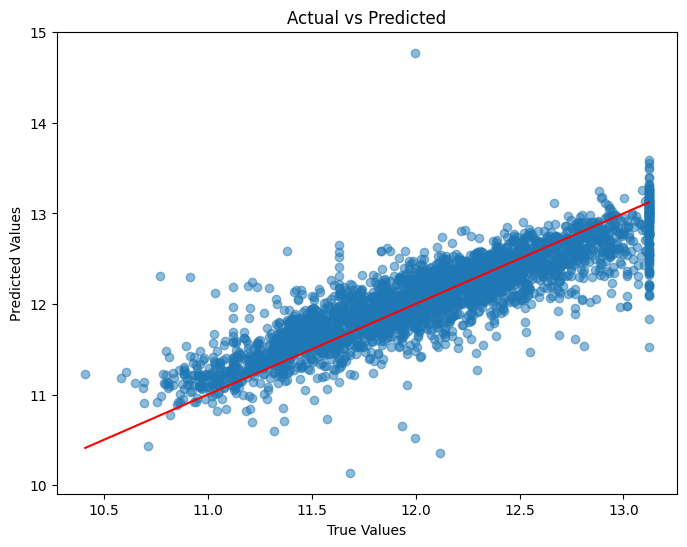

In [70]:
plt.figure(figsize=(8,6))

plt.scatter(y_val, y_val_pred, alpha=0.5)

# perfect prediction line
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    color="red"
)

plt.xlabel("True Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted")

plt.show()

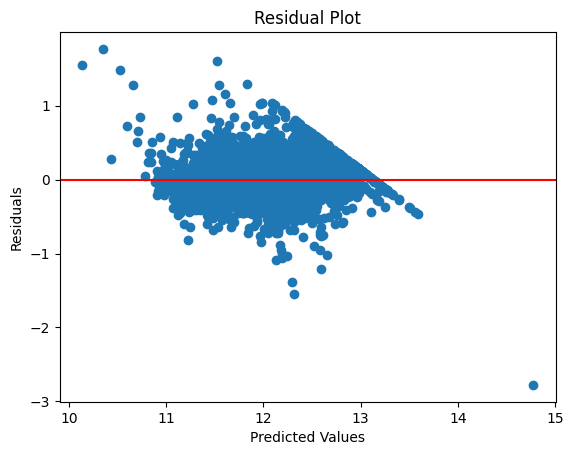

In [71]:
residuals = y_val - y_val_pred

plt.scatter(y_val_pred, residuals)

plt.axhline(0, color="red")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

In [76]:


# -----------------------------------
# CALCULATE METRICS
# -----------------------------------
y_test_pred = model.predict(X_test_new)

rmse_test = root_mean_squared_error(
    y_test,
    y_test_pred
)

r2_score_test = r2_score(
    y_test,
    y_test_pred
)

print(f"Root Mean Squared Error: {rmse_test:.4f}")
print(f"R^2 Score: {r2_score_test:.4f}")
y_train_pred = model.predict(X_train_new)

train_rmse = root_mean_squared_error(
    y_train,
    y_train_pred
)

train_r2 = r2_score(
    y_train,
    y_train_pred
)

print(train_rmse)
print(train_r2)

# addRecord(rmse=rmse_test,changes="using our model to get coef Threshold- 0.01",r2_test=r2_score_test,r2_train=train_r2,x_train=X_train_new,x_test=X_test_new)

Root Mean Squared Error: 0.3095
R^2 Score: 0.7132
0.28044722095153846
0.7555272763207165
